# EDA: дневные котировки акций MOEX, доска TQBR

Данные: `share/moex_tqbr_daily/v=20261109` (S3 проекта), выгрузка MOEX ISS, все 24 колонки.
Период: с 2020-01-03 по 2025-06-30. Данные после 30.06.2025 не используются (холдаут).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data"
END = "2025-06-30"  # граница холдаута: позже не смотрим

df = pd.concat([pd.read_parquet(f"{BASE}/year={y}/part.parquet") for y in range(2020, 2026)], ignore_index=True)
df["TRADEDATE"] = pd.to_datetime(df["TRADEDATE"])
df = df[df["TRADEDATE"] <= END].reset_index(drop=True)
tr = df[df["NUMTRADES"] > 0]  # строки со сделками

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.Series({
    "строк": len(df),
    "дат": df.TRADEDATE.nunique(),
    "дат со сделками": tr.TRADEDATE.nunique(),
    "бумаг": df.SECID.nunique(),
    "бумаг со сделками": tr.SECID.nunique(),
    "период": f"{df.TRADEDATE.min():%Y-%m-%d} ... {df.TRADEDATE.max():%Y-%m-%d}",
}).to_frame("значение")

,значение
строк,359438
дат,1390
дат со сделками,1372
бумаг,329
бумаг со сделками,312
период,2020-01-03 ... 2025-06-30


## 1. Состав и покрытие

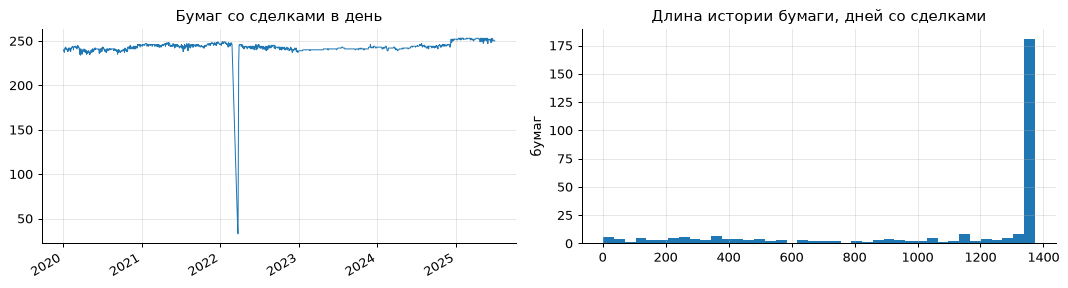

,значение
медиана бумаг в день,243
появились позже начала периода,69
ушли раньше конца периода,58


TRADEDATE,2020,2021,2022,2023,2024,2025
"строк без сделок, %",8.2,8.5,15.5,2.3,2.8,3.0


In [2]:
per = tr.groupby("SECID").agg(first=("TRADEDATE", "min"), last=("TRADEDATE", "max"),
                              days=("TRADEDATE", "nunique"), med_value=("VALUE", "median"))
d0, d1 = tr.TRADEDATE.min(), tr.TRADEDATE.max()
n_daily = tr.groupby("TRADEDATE").SECID.nunique()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
n_daily.plot(ax=ax[0], lw=0.8, title="Бумаг со сделками в день", xlabel="")
per.days.plot.hist(bins=40, ax=ax[1], title="Длина истории бумаги, дней со сделками")
ax[1].set_ylabel("бумаг")
plt.tight_layout(); plt.show()

display(pd.Series({
    "медиана бумаг в день": int(n_daily.median()),
    "появились позже начала периода": int((per["first"] > d0 + pd.Timedelta(days=30)).sum()),
    "ушли раньше конца периода": int((per["last"] < d1 - pd.Timedelta(days=30)).sum()),
}).to_frame("значение"))
df.NUMTRADES.eq(0).groupby(df.TRADEDATE.dt.year).mean().mul(100).round(1).to_frame("строк без сделок, %").T

**Выводы**
- В день торгуется около 243 бумаг. За период 69 бумаг появились и 58 ушли, поэтому состав для моделей нужно брать на каждую дату, а не по текущему списку: иначе будет ошибка выжившего.
- Строк без сделок 8% в 2020-2021, 15,5% в 2022 (закрытие рынка 28.02-23.03.2022) и 2-3% с 2023 года. Перед расчётами нужен фильтр `NUMTRADES > 0`.

## 2. Качество данных

In [3]:
eps = 1e-4
checks = pd.Series({
    "HIGH < LOW": (tr.HIGH < tr.LOW).sum(),
    "OPEN или CLOSE вне [LOW, HIGH]": ((tr[["OPEN", "CLOSE"]].lt(tr.LOW, axis=0)) | (tr[["OPEN", "CLOSE"]].gt(tr.HIGH, axis=0))).any(axis=1).sum(),
    "WAPRICE вне [LOW, HIGH]": ((tr.WAPRICE < tr.LOW * (1 - eps)) | (tr.WAPRICE > tr.HIGH * (1 + eps))).sum(),
    "пустые OHLC при сделках": tr[["OPEN", "HIGH", "LOW", "CLOSE"]].isna().any(axis=1).sum(),
    "|VALUE / (VOLUME * WAPRICE) - 1| > 1%": ((tr.VALUE / (tr.VOLUME * tr.WAPRICE) - 1).abs() > 0.01).sum(),
}).to_frame(f"строк из {len(tr)}")
fill = df.notna().mean().mul(100).round(1)
display(checks, fill[fill < 90].to_frame("заполнено, %"))

# дневные лог-доходности по цене последней сделки между соседними днями со сделками
t = tr.sort_values(["SECID", "TRADEDATE"]).copy()
g = t.groupby("SECID")
t["prev_close"], t["prev_date"] = g.CLOSE.shift(), g.TRADEDATE.shift()
t["pause_days"] = (t.TRADEDATE - t.prev_date).dt.days
t["r"] = np.log(t.CLOSE / t.prev_close)
t["jump"] = t.r.abs() > np.log(2)  # цена изменилась больше чем вдвое за день
t["closure"] = (t.prev_date < "2022-02-28") & (t.TRADEDATE > "2022-03-23")  # переход через закрытие рынка

jumps = t[t.jump].assign(
    во_сколько_раз=lambda x: np.exp(x.r.abs()).round(1),
    направление=lambda x: np.where(x.r > 0, "вверх", "вниз"),
)
print("дней с изменением цены больше чем вдвое:", len(jumps))
jumps.sort_values("VALUE", ascending=False)[
    ["TRADEDATE", "SECID", "prev_close", "CLOSE", "во_сколько_раз", "направление", "pause_days"]].head(8)

,строк из 333669
HIGH < LOW,0
"OPEN или CLOSE вне [LOW, HIGH]",0
"WAPRICE вне [LOW, HIGH]",205
пустые OHLC при сделках,0
|VALUE / (VOLUME * WAPRICE) - 1| > 1%,387


,"заполнено, %"
MARKETPRICE2,71.2
ADMITTEDQUOTE,55.3
ADMITTEDVALUE,56.4
TRADE_SESSION_DATE,6.0


дней с изменением цены больше чем вдвое: 14


,TRADEDATE,SECID,prev_close,CLOSE,во_сколько_раз,направление,pause_days
324371,2024-07-15,VTBR,0.01993,92.9500,4663.8,вверх,7.0
318239,2024-02-21,TRNFP,166850.00000,1583.5000,105.4,вниз,7.0
267926,2024-08-22,BELU,4680.00000,714.0000,6.6,вниз,7.0
278241,2024-04-08,GMKN,15054.00000,152.9600,98.4,вниз,7.0
347101,2025-03-27,PLZL,19017.00000,1867.6000,10.2,вниз,6.0
242971,2023-01-19,ROLO,7.95500,0.8999,8.8,вниз,9.0
175766,2022-07-12,POGR,3.78000,0.8700,4.3,вниз,1.0
93160,2021-07-12,LNZLP,6020.00000,2845.0000,2.1,вниз,3.0


**Выводы**
- Цены согласованы: HIGH не ниже LOW, OPEN и CLOSE всегда внутри диапазона дня, `VALUE` совпадает с `VOLUME * WAPRICE` с точностью 1% в 99,9% строк.
- `WAPRICE` в 205 строках выходит за [LOW, HIGH], как цену его без проверки брать не стоит.
- `ADMITTEDQUOTE`, `ADMITTEDVALUE`, `MARKETPRICE2` и `TRADE_SESSION_DATE` заполнены на 6-71%, для признаков они не годятся.
- В 14 днях цена изменилась больше чем вдвое. У крупнейших (VTBR, TRNFP, GMKN, PLZL, BELU) перед этим торги стояли около недели, а цена изменилась кратно (TRNFP и GMKN примерно в 100 раз, PLZL в 10, VTBR в 4664 раза): это похоже на дробление или консолидацию акций. Без корректировки такие дни дают ложные доходности, дальше они исключены.

## 3. Ликвидность и активность

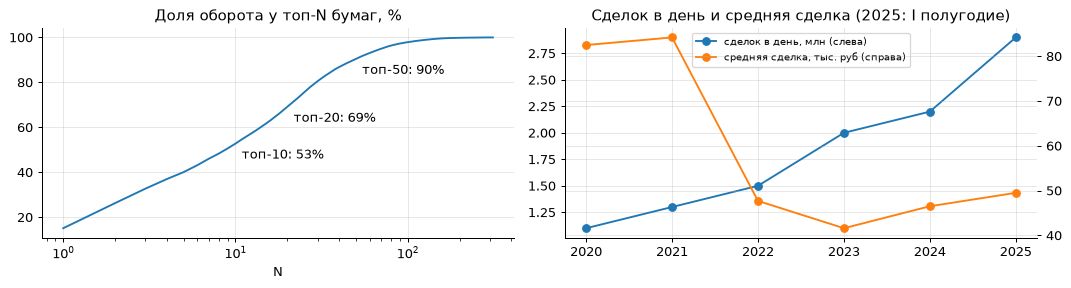

,"оборот в день, млрд руб","сделок в день, млн","средняя сделка, тыс. руб"
TRADEDATE,,,
2020,91.1,1.1,82.5
2021,108.3,1.3,84.2
2022,70.5,1.5,47.7
2023,81.9,2.0,41.6
2024,104.1,2.2,46.5
2025,141.6,2.9,49.5


,бумаг
медианный оборот >= 10 млн руб,128
медианный оборот >= 100 млн руб,69
медианный оборот >= 1 млрд руб,22


In [4]:
tot = tr.groupby("SECID").VALUE.sum().sort_values(ascending=False)
cum = tot.cumsum() / tot.sum() * 100
yr = tr.groupby(tr.TRADEDATE.dt.year)
act = pd.DataFrame({
    "оборот в день, млрд руб": yr.VALUE.sum() / yr.TRADEDATE.nunique() / 1e9,
    "сделок в день, млн": yr.NUMTRADES.sum() / yr.TRADEDATE.nunique() / 1e6,
    "средняя сделка, тыс. руб": yr.VALUE.sum() / yr.NUMTRADES.sum() / 1e3,
}).round(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].plot(np.arange(1, len(cum) + 1), cum.values)
ax[0].set(xscale="log", title="Доля оборота у топ-N бумаг, %", xlabel="N")
for n in (10, 20, 50):
    ax[0].annotate(f"топ-{n}: {cum.iloc[n - 1]:.0f}%", (n, cum.iloc[n - 1]), textcoords="offset points", xytext=(5, -12))
ax[1].plot(act.index, act["сделок в день, млн"], "o-", label="сделок в день, млн (слева)")
ax2 = ax[1].twinx()
ax2.plot(act.index, act["средняя сделка, тыс. руб"], "o-", color="C1", label="средняя сделка, тыс. руб (справа)")
ax[1].set(title="Сделок в день и средняя сделка (2025: I полугодие)")
ax[1].legend(handles=ax[1].get_lines() + ax2.get_lines(), loc="upper center", fontsize=8)
plt.tight_layout(); plt.show()

display(act)
pd.Series({f"медианный оборот >= {k}": int((per.med_value >= v).sum())
           for k, v in {"10 млн руб": 1e7, "100 млн руб": 1e8, "1 млрд руб": 1e9}.items()}).to_frame("бумаг")

**Выводы**
- Оборот сосредоточен в немногих бумагах: на топ-10 приходится 53% оборота, на топ-50 90%. Медианный оборот от 100 млн руб в день только у 69 бумаг, от 1 млрд руб у 22.
- Сделок в день стало в 2,6 раза больше (1,1 млн в 2020, 2,9 млн в I полугодии 2025), а средняя сделка в 2022 упала с 84 до 48 тыс. руб и осталась на уровне 40-50 тыс.: сделки стали мельче и многочисленнее.
- Средний дневной оборот провалился в 2022 (70 млрд руб) и к 2025 вырос до 142 млрд руб.

## 4. Доходности: хвосты и режимы

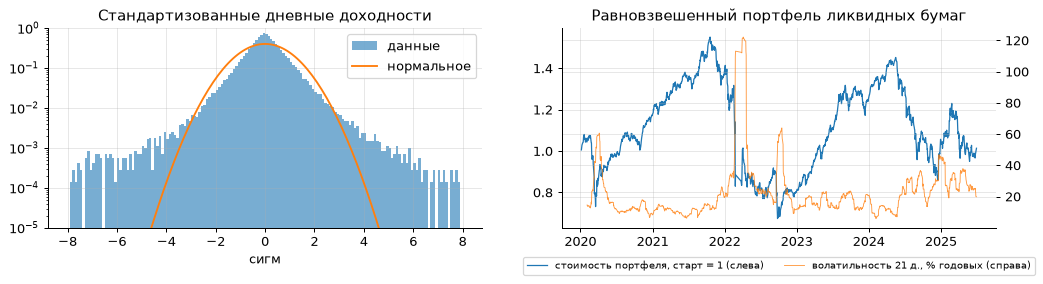

,значение
ликвидных бумаг,63
наблюдений,72903
"ст. отклонение, %",2.64
эксцесс,50.3
эксцесс без 24.02.2022,15.7
|z| > 4: во сколько раз чаще нормального,100
"худший день портфеля, %",-27.3 (2022-02-24)
"макс. просадка, %",-57 (2022-09-26)


TRADEDATE,2020,2021,2022,2023,2024,2025
"волатильность портфеля, % год.",22.7,13.4,46.0,17.1,24.5,28.2


In [5]:
# ликвидные бумаги: не меньше 250 дней со сделками и медианный дневной оборот от 100 млн руб
liq = per.index[(per.days >= 250) & (per.med_value >= 1e8)]
R = t[t.SECID.isin(liq) & t.r.notna() & ~t.jump & ~t.closure].copy()
z = R.groupby("SECID").r.transform(lambda s: (s - s.mean()) / s.std())

ew = np.expm1(R.r).groupby(R.TRADEDATE).mean()  # равновзвешенный портфель ликвидных бумаг
wealth = (1 + ew).cumprod()
vol21 = ew.rolling(21).std() * np.sqrt(252) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
grid = np.linspace(-8, 8, 161)
ax[0].hist(z, bins=grid, density=True, alpha=0.6, label="данные")
ax[0].plot(grid, np.exp(-grid ** 2 / 2) / np.sqrt(2 * np.pi), label="нормальное")
ax[0].set(yscale="log", ylim=(1e-5, 1), title="Стандартизованные дневные доходности", xlabel="сигм")
ax[0].legend()
ax[1].plot(wealth.index, wealth.values, lw=1, label="стоимость портфеля, старт = 1 (слева)")
ax3 = ax[1].twinx()
ax3.plot(vol21.index, vol21.values, color="C1", lw=0.7, alpha=0.8, label="волатильность 21 д., % годовых (справа)")
ax[1].set(title="Равновзвешенный портфель ликвидных бумаг")
ax[1].legend(handles=ax[1].get_lines() + ax3.get_lines(), loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

normal_4 = 6.334e-5  # P(|Z| > 4) для нормального
display(pd.Series({
    "ликвидных бумаг": len(liq),
    "наблюдений": len(R),
    "ст. отклонение, %": round(R.r.std() * 100, 2),
    "эксцесс": round(R.r.kurt(), 1),
    "эксцесс без 24.02.2022": round(R.r[R.TRADEDATE != "2022-02-24"].kurt(), 1),
    "|z| > 4: во сколько раз чаще нормального": int(round((z.abs() > 4).mean() / normal_4)),
    "худший день портфеля, %": f"{ew.min() * 100:.1f} ({ew.idxmin():%Y-%m-%d})",
    "макс. просадка, %": f"{(wealth / wealth.cummax() - 1).min() * 100:.0f} ({(wealth / wealth.cummax()).idxmin():%Y-%m-%d})",
}).to_frame("значение"))
(ew.groupby(ew.index.year).std() * np.sqrt(252) * 100).round(1).to_frame("волатильность портфеля, % год.").T

**Выводы**
- Хвосты очень тяжёлые: эксцесс дневных доходностей 50 (16 без одного дня 24.02.2022), движения больше 4 сигм случаются в 100 раз чаще, чем при нормальном распределении. Для оценки риска и функций потерь нужны устойчивые к выбросам методы.
- Режимы рынка сильно различаются: годовая волатильность равновзвешенного портфеля ликвидных бумаг от 13% (2021) до 46% (2022). Худший день 24.02.2022 (-27%), максимальная просадка -57% к 26.09.2022.

## 5. Зависимости во времени и между бумагами

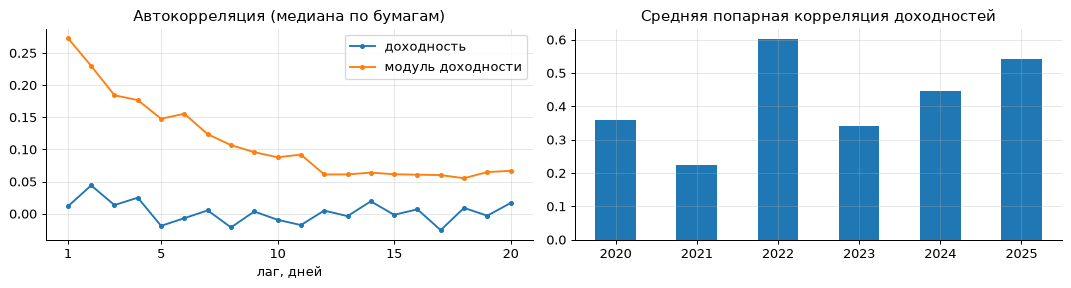

,лаг 1,лаг 5,лаг 20
доходность,0.012,-0.019,0.017
модуль доходности,0.273,0.148,0.067


,2020,2021,2022,2023,2024,2025
средняя корреляция,0.36,0.22,0.6,0.34,0.45,0.54


In [6]:
def acf(s, k):
    s = s - s.mean()
    return (s.values[k:] * s.values[:-k]).sum() / (s.values ** 2).sum()

lags = range(1, 21)
by_sec = [s.reset_index(drop=True) for _, s in R.groupby("SECID").r if len(s) > 300]
acf_r = pd.Series([np.median([acf(s, k) for s in by_sec]) for k in lags], index=lags)
acf_abs = pd.Series([np.median([acf(s.abs(), k) for s in by_sec]) for k in lags], index=lags)

wide = R.pivot_table(index="TRADEDATE", columns="SECID", values="r")
corr_y = {}
for y, part in wide.groupby(wide.index.year):
    c = part.dropna(axis=1, thresh=100).corr().values
    corr_y[y] = np.nanmean(c[np.triu_indices_from(c, 1)])
corr_y = pd.Series(corr_y)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
pd.DataFrame({"доходность": acf_r, "модуль доходности": acf_abs}).plot(ax=ax[0], marker=".", title="Автокорреляция (медиана по бумагам)", xlabel="лаг, дней")
ax[0].set_xticks([1, 5, 10, 15, 20])
corr_y.plot.bar(ax=ax[1], title="Средняя попарная корреляция доходностей", xlabel="", rot=0)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"лаг 1": [acf_r[1], acf_abs[1]], "лаг 5": [acf_r[5], acf_abs[5]], "лаг 20": [acf_r[20], acf_abs[20]]},
                     index=["доходность", "модуль доходности"]).round(3))
corr_y.round(2).to_frame("средняя корреляция").T

**Выводы**
- Автокорреляции доходностей почти нет (0,01 на лаге 1), а у модуля доходности она 0,27 и держится до 20 дней. Направление по прошлым ценам не предсказать, величину движения (волатильность) можно.
- Бумаги движутся вместе: средняя попарная корреляция от 0,22 (2021) до 0,60 (2022) и растёт в кризисы. Диверсификация слабеет именно тогда, когда нужна, это важно для риск-модуля.

## 6. Оборот и волатильность

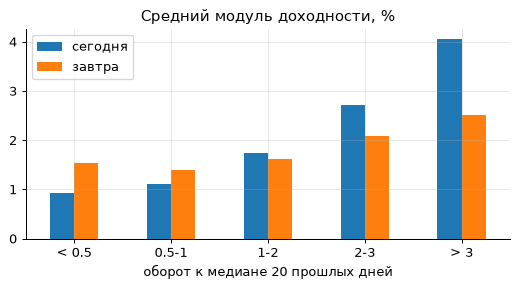

ранговая корреляция |r| и относительного оборота: 0.374 | r и относительного оборота: 0.065


,"доля дней, %",сегодня,завтра
оборот к медиане,,,
< 0.5,10.44,0.93,1.54
0.5-1,40.79,1.12,1.40
1-2,35.29,1.74,1.63
2-3,7.78,2.71,2.08
> 3,5.70,4.07,2.52


In [7]:
R["rel_value"] = R.VALUE / R.groupby("SECID").VALUE.transform(lambda s: s.shift().rolling(20, min_periods=10).median())
R["abs_r_next"] = R.groupby("SECID").r.shift(-1).abs()
bucket = pd.cut(R.rel_value, [0, 0.5, 1, 2, 3, np.inf], labels=["< 0.5", "0.5-1", "1-2", "2-3", "> 3"])
tab = R.groupby(bucket, observed=True).agg(**{
    "доля дней, %": ("r", lambda s: len(s) / R.rel_value.notna().sum() * 100),
    "сегодня": ("r", lambda s: s.abs().mean() * 100),
    "завтра": ("abs_r_next", lambda s: s.mean() * 100),
})
tab.index.name = "оборот к медиане"

tab[["сегодня", "завтра"]].plot.bar(figsize=(6, 3.3), rot=0, xlabel="оборот к медиане 20 прошлых дней",
                                    title="Средний модуль доходности, %")
plt.tight_layout(); plt.show()
rank_corr = lambda a, b: np.corrcoef(a.rank(), b.rank())[0, 1]
m = R.rel_value.notna()
print("ранговая корреляция |r| и относительного оборота:", round(rank_corr(R.r[m].abs(), R.rel_value[m]), 3),
      "| r и относительного оборота:", round(rank_corr(R.r[m], R.rel_value[m]), 3))
tab.round(2)

**Выводы**
- В дни, когда оборот больше чем втрое выше обычного (5,7% дней), средний модуль доходности 4,1% против 1,1% в обычные дни, а на следующий день 2,5% против 1,4%.
- Ранговая связь относительного оборота с величиной движения 0,37, с направлением 0,07. Всплеск оборота хорошо отмечает дни событий и помогает прогнозу волатильности, но не направления.

## 7. Ночной гэп и день недели

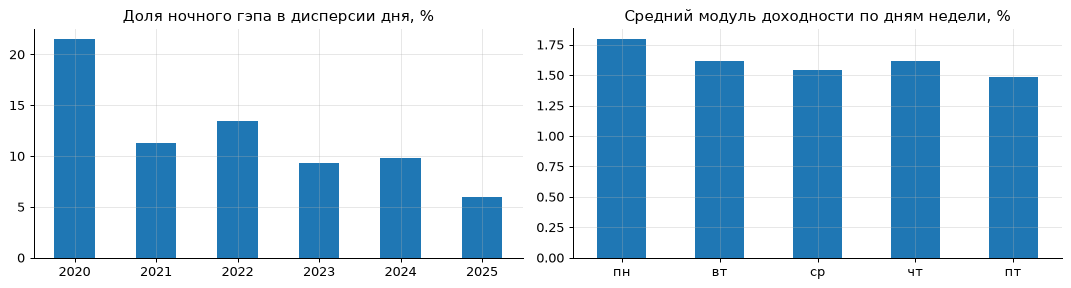

TRADEDATE,2020,2021,2022,2023,2024,2025
"доля ночного гэпа, %",21.5,11.3,13.4,9.3,9.8,6.0


,пн,вт,ср,чт,пт
"средний |r|, %",1.79,1.62,1.54,1.62,1.49


,значение
"доля ночного гэпа за весь период, %",12.60
"средний |гэп| после выходных и праздников, %",0.61
"средний |гэп| между соседними днями, %",0.38


In [8]:
R["r_on"] = np.log(R.OPEN / R.prev_close)   # от закрытия прошлого дня до открытия
R["r_id"] = np.log(R.CLOSE / R.OPEN)        # внутри дня
on2 = (R.r_on ** 2).groupby(R.TRADEDATE.dt.year).sum()
id2 = (R.r_id ** 2).groupby(R.TRADEDATE.dt.year).sum()
wd = R[R.TRADEDATE.dt.day_of_week < 5].groupby(R.TRADEDATE.dt.day_of_week).r.apply(lambda s: s.abs().mean() * 100)
wd.index = ["пн", "вт", "ср", "чт", "пт"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
(on2 / (on2 + id2) * 100).plot.bar(ax=ax[0], rot=0, xlabel="", title="Доля ночного гэпа в дисперсии дня, %")
wd.plot.bar(ax=ax[1], rot=0, title="Средний модуль доходности по дням недели, %")
plt.tight_layout(); plt.show()
display((on2 / (on2 + id2) * 100).round(1).to_frame("доля ночного гэпа, %").T, wd.round(2).to_frame("средний |r|, %").T)
pd.Series({
    "доля ночного гэпа за весь период, %": round((R.r_on ** 2).sum() / ((R.r_on ** 2).sum() + (R.r_id ** 2).sum()) * 100, 1),
    "средний |гэп| после выходных и праздников, %": round(R.r_on[R.pause_days > 1].abs().mean() * 100, 2),
    "средний |гэп| между соседними днями, %": round(R.r_on[R.pause_days == 1].abs().mean() * 100, 2),
}).to_frame("значение")

**Выводы**
- Ночной гэп (от закрытия до открытия) даёт 13% дневной дисперсии, и его доля падает: 21% в 2020, 6% в 2025. Основное движение цены происходит внутри торгового дня.
- После выходных и праздников гэп больше (0,61% против 0,38%), понедельник самый волатильный день (1,79% против 1,49% в пятницу): информация за выходные попадает в цену в первый торговый день.